## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [13]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Nina Breen

**Date:** 10/19/26

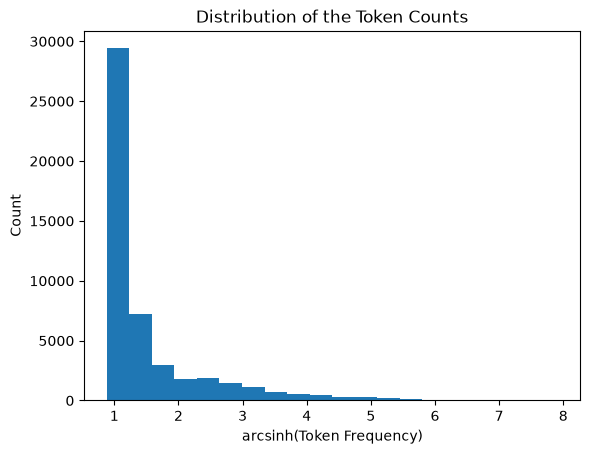

In [ ]:
# Your Phase 1 solution to the problem goes here.
# Q1 - making histogram of the occurance of tokens
import matplotlib.pyplot as plt
import numpy as np

token_counts = list(token_count.values()) # selecting only the values and then making that into a list

arcsinh_token_counts = np.arcsinh(token_counts) # applying arcsinh because the data is skewed

plt.hist(arcsinh_token_counts, bins = 20)
plt.title('Distribution of the Token Counts')
plt.xlabel('arcsinh(Token Frequency)')
plt.ylabel('Count')

plt.show()

# This histogram shows that most token appear at a lower frequency. Even after normalization, there seems to still be a skew meaning that there are a lot of tokens happening at lower frequencies. 


**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

In [28]:
import pandas as pd
df = pd.read_parquet('./data/Phishing_clean.parquet')

# splitting the data 80/20:
from sklearn.model_selection import train_test_split
eval_x_raw = df.drop(columns = ['Email Type'])
eval_y = df['Email Type']
(x_train, x_valid, y_train, y_valid,) = train_test_split(eval_x_raw, eval_y, test_size = 0.20, random_state = 7)



In [29]:
# regression of y - what is R^2 on the test set and training set
from sklearn.linear_model import LinearRegression
sk_fit = LinearRegression().fit(x_train, y_train)

print("R-squared - training set:", round(sk_fit.score(x_train, y_train), 4))
print("R-squared - test set:", round(sk_fit.score(x_valid, y_valid), 4))


R-squared - training set: 0.7657
R-squared - test set: 0.6682


In [ ]:
# What word has the largest coefficients in absolute value and most strongly influence predictions:
coefficients = sk_fit.coef_
word_names = eval_x_raw.columns

coef_df = pd.DataFrame({
    'Word': word_names,
    'Coefficient': coefficients,
    'Absolute_Coef': np.abs(coefficients)
})

top_words = coef_df.sort_values(by = 'Absolute_Coef', ascending=False).head(5)
print('Top words influencing predictions:\n', top_words)

# The word that has the largest coefficient and strongest influence on the prediction is helvetica. Because the non-absolute coefficient is positive, that means that this predicts the email to be a phishing scam email.

Top words influencing predictions:
                    Word  Coefficient  Absolute_Coef
1406         helvetica,     1.024227       1.024227
1504  background-image:    -1.018343       1.018343
1047         font-size:    -0.997077       0.997077
2094           #000000;     0.924223       0.924223
2666           #331f30;     0.924223       0.924223


**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

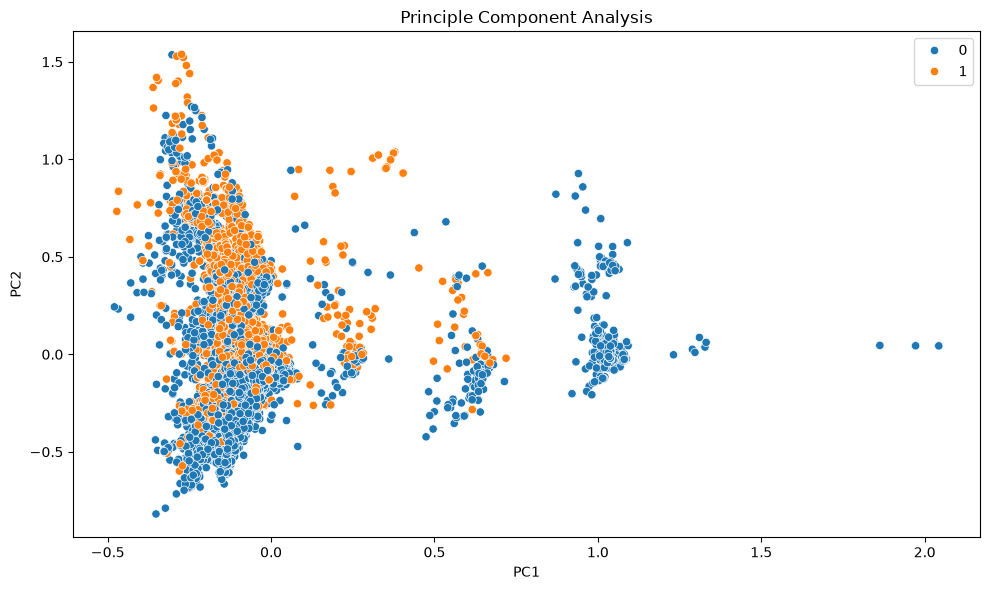

In [ ]:
# the email column is already removed in the variable exal_x_raw // two components means that n = 2
from sklearn.decomposition import PCA
import seaborn as sns

pca_emails = PCA(n_components = 2).fit(eval_x_raw)
x_pca_sklearn = pca_emails.transform(eval_x_raw)

# making a df to hold the pca results so we can plot it
pca_df = pd.DataFrame(data = x_pca_sklearn, columns = ['PC1', 'PC2'])
pca_df['Email Type'] = eval_y.values

# plotting the scatter plot
fig, ax = plt.subplots(figsize = (10,6))
sns.scatterplot(
    data = pca_df, 
    x = 'PC1', 
    y = 'PC2',
    hue = 'Email Type',
    ax = ax)

ax.set_title('Principle Component Analysis')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend()

plt.tight_layout()
plt.show()

# There is a large clump of scam and legitamite emails on the left side of the graph. This means that 2 components do not capture enough variance to differentiate the email types.
# However, there is a large group of legitamite emails with no scam emails on the right side of the graph indicating that high scored on PC1 indicate that the emails are legitament. 


**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [ ]:
# running PCA analysis
pca_emails_multiple = PCA(n_components=2610).fit(eval_x_raw)
x_pca_emails_multiple = pca_emails_multiple.transform(eval_x_raw)

# splitting the pca data:
x_train_pca, x_valid_pca, y_train_pca, y_valid_pca = train_test_split(x_pca_emails_multiple, eval_y, test_size = 0.20, random_state = 7)

# ftting the linear regression model + getting R^2 values
pca_lr_model = LinearRegression().fit(x_train_pca, y_train_pca)

print("R-squared - training set:", round(pca_lr_model.score(x_train_pca, y_train_pca), 4))
print("R-squared - test set:", round(pca_lr_model.score(x_valid_pca, y_valid_pca), 4))

# Q2 R-squared - training set for linear regression: 0.7657
# Q2 R-squared - test set for linear regr: 0.6682

#

R-squared - training set: 0.7647
R-squared - test set: 0.6721


In [ ]:
# data is already split from Q2 so reusing that

# fitting pca based on the training set:
pca_emails_multiple = PCA(n_components = 2610).fit(x_train)
x_train_pca = pca_emails_multiple.transform(x_train)

#doing pca on the test set:
x_valid_pca = pca_emails_multiple.transform(x_valid)

# linear regression:
pca_lr_model = LinearRegression().fit(x_train_pca, y_train)

print("R-squared - training set:", round(pca_lr_model.score(x_train_pca, y_train), 4))
print("R-squared - test set:", round(pca_lr_model.score(x_valid_pca, y_valid), 4))

# The test set R^2 increased slightly between the linear regression on the original data vs the pca (0.6682 for the original data and 0.6718 for the pca).
# Additionally, the R^ squared value for the training set decreased slightly (0.7657 for the original data and 0.7648 for the pca).
# This means that the test set increased in correctness while the training set decreased meaning it is picking up less random noise. 


R-squared - training set: 0.7648
R-squared - test set: 0.6718


**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.


In [ ]:
# There are multiple advantages of using principal components to run the high-dimensional regression.
# By using pca, you are able to filter out noise a lot easier. By using not all PCA values, you 
# reduce the amount of noise that is in the analysis and reduce linear regression model fitting 
# just because of noise. There is also less overfitting, this is because there are less dimensions and the model
# can focus on just signals. This helps the test set and unseen data have more accurate predictions.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 0a44bdc3ddf832179bd4df119055d65708b78ad2
- **AI tool and model used:** Claude - Sonnet

### *Prompts used

1. Attached is my Jupyter Notebook data science intro to machine learning assignment. Can you go through my work and check that it is correct, and give any feedback/ any changes you recommend? Go through all questions and all the subparts of each. 
When giving the changes, show me what you want to change, what you want to change it to, and why you want to change it.
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Q1: Histogram of token occurrences

What’s right: You pulled the counts correctly with token_count.values() and made a histogram.

Change 1: Show the raw distribution (or use a log axis), and name the transformation correctly.

Currently:

python
arcsinh_token_counts = np.arcsinh(token_counts)
plt.hist(arcsinh_token_counts, bins=20)

Change to:

python
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(token_counts, bins=50)
axes[0].set_yscale('log')
axes[0].set_title('Raw token counts (log y-axis)')
axes[0].set_xlabel('Occurrences of token')
axes[0].set_ylabel('Number of tokens (log)')

axes[1].hist(np.log10(token_counts), bins=30)
axes[1].set_title('log10(token counts)')
axes[1].set_xlabel('log10(Occurrences)')
plt.tight_layout(); plt.show()

Why: The question asks about the histogram of occurrences, so the reader should see the raw shape first. The raw shape is the point of the question, and the transform hides it. arcsinh is meant for data that includes zeros, and every count here is at least 1, so a plain log is simpler and easier to explain.
2. Change 2: Rewrite the interpretation with specifics.

Currently: “most token appear at a lower frequency. Even after normalization, there seems to still be a skew...”

Change to something like:

The distribution is extremely right-skewed and heavy-tailed (Zipf-like). There are 48,691 unique tokens across about 277k total, and about 60% appear only once. The median token appears once, while the most common (“new”) appears 1,365 times. A few tokens account for a large share of all occurrences, and most tokens are rare.

Why: “Normalization” is the wrong word, because you transformed the data and didn’t normalize it. Your description is also correct but vague. The numbers back it up and show you checked.
3. 2.2 R²: Correct (0.7657 train, 0.6682 test), but you never state the answer or what it means. Add:

python
#Train R^2 = 0.7657, test R^2 = 0.6682. The ~0.10 gap shows the model is overfitting:
#2,711 features vs ~14.9k training emails, so it fits some noise in the training set.

2.3 Top coefficients: The code is right, but the answer is incomplete in two ways.

Change 3: Report the top several words, with signs, and read them in both directions.

Currently, you comment only on “helvetica”. The question asks “what words” (plural). From your output:

helvetica, (+1.02) pushes toward scam.
background-image: (-1.02) and font-size: (-1.00) push toward legitimate.
#000000; and #331f30; (+0.92) push toward scam.

Suggested wording: “Because every feature is binary, coefficients are directly comparable. A coefficient of about 1.0 means the token’s presence raises the predicted scam probability by about 1, holding other tokens fixed.”
4. Change 4: Add a caveat about the large coefficients.

Suggested wording: “Many of the largest coefficients belong to rare tokens. helvetica, appears in only 12 training emails. The matrix also has duplicate or collinear columns (67 exact duplicate columns, rank about 2,642 vs 2,711 columns). #000000; and #331f30; having an identical coefficient of 0.924223 is a symptom of this. So these coefficients are unstable and shouldn’t be read as strong causal drivers.”

Why: This is the real reason PCA helps in Q5, so connecting the two strengthens both answers. Also note that tokens like helvetica, and #000000; are HTML/CSS fragments, so the model may be partly detecting HTML-formatted emails and not scam language.
5. Change 5: Fix the plot’s overplotting.

Currently:

python
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type', ax=ax)

Change to:

python
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type',
                alpha=0.3, s=12, ax=ax)

Why: With 18,634 points, they pile on top of each other and the clump looks like solid color. Transparency makes density visible. Also remove the redundant ax.legend() call, because seaborn already draws the legend, and re-calling it can overwrite the legend title.
6. Change 6: Strengthen the interpretation.

Currently: “There is a large clump... 2 components do not capture enough variance...”

Add numbers and the pattern you missed:

python
print(pca_emails.explained_variance_ratio_)  # ~[0.011, 0.009]

The two components explain only about 2% of the variance, which is why the classes overlap heavily. There are still patterns: PC1 > 1 is entirely legitimate email (0% scam), and high PC2 skews toward scam (about 69% scam for PC2 > 0.5 vs about 2% for PC2 < -0.5).

Why: Your PC1 observation is right, but you missed that PC2 separates the classes too, and the variance figure supports your “not enough variance” claim.
7. 
Change 7: Delete the first Q4 cell.

That cell fits PCA on all the data and then splits. This leaks test-set information into the PCA step. It is unsupervised leakage, so the effect is tiny, but it’s still the wrong order. Your second cell (fit PCA on x_train only, then transform x_valid) is correct, and it’s the one your commentary matches. Leaving both cells in is confusing, and the first cell shows 0.6721 while the second shows 0.6718.
8. Change 8: Fix the comparison.

Currently: “test set increased in correctness while the training set decreased meaning it is picking up less random noise.”

Change to:

Linear regression: train 0.7657 / test 0.6682. PCA regression (2,610 components): train 0.7648 / test 0.6718. These are essentially identical. The differences (0.0009 and 0.0036) are too small to claim PCA is better. This makes sense: the data has rank of about 2,640, so 2,610 components retain nearly all the information and the PCA regression is almost the same model as plain OLS. It only drops the roughly 100 smallest-variance directions.
9. Your points (noise filtering, less overfitting, fewer dimensions) are on the right track. These changes would tighten it:

“reduce linear regression model fitting just because of noise” is unclear. Replace with: “dropping low-variance components acts as regularization, so the model can’t fit noise in those directions.”
“By using not all PCA values” should be “not all principal components.”
Add the collinearity point from Q2: principal components are uncorrelated (orthogonal), so they remove the multicollinearity and rank deficiency in the one-hot matrix, which makes the regression better conditioned and more stable.
Add an honest caveat: PCA is unsupervised, so it keeps high-variance directions that may not predict the target. It only helps if you choose the number of components well, ideally with validation data. Tie it to Q4: at 2,610 components you gain almost nothing.


### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | modify | I think this is a better way of visualizing the distribution of occurances of the tokens. However, I did not choose to use log because I think the arcsinh better. The log y-axis helped show the actual distibution.|
| 2 | Accept | I think that the suggestion explains the distribution more clearly than what I wrote the first time. It just has more details which just creates a better understanding of the data. |
| 3 | Modify | When I was reading the question, I read that it was asking for one word not words. This is a good catch by AI. I did still include multiple words in the output of the cell but in the comment I only mentioned one word. I am going to add the multiple words to the comment that have the highest coefficients. I am also going to add the explanation that it suggests because it is correct and give good context to the answer. However, I do not think the suggested wording that it gave makes sense to add for this question.|
| 4 | reject | I think what it is suggesting to add is interesting and makes sense in this context. However, I do not think that it is needed to answer the question and would just make the cell seem too wordy, so I am not going to add it. |
| 5 | modify | I think making the points transparent makes the graph look really ugly and hard to get meaning out of. I also think making the points smaller is not something that needs to happen. I will take out the ax.legend because I did not know that a legend was automatically populated.  |
| 6 | Accept | I think this is a good way to describe the graph. Adding more details to the explanation allows the reader to really understand what is happening in the graph. I also think it is good information to know that pc1 only explains 2% of the variation in the dataset -- I know that most pca graphs include that percentage in the axes title so it would be a good thing to add here. |
| 7 | Accept | I made a mistake in phase 1. I was trying to decide how to split up the pca values and I realized that what I was first done (the first cell) was wrong so I made the second cell and did it that way. I did not realize that I forgot to delete the first cell. This is a really good mistake to catch. |
| 8 | reject | I think I made some good observations and it basically told me that I was overclaiming. I disagree. Yes, there is a small change, but it is still a change and I am going to tal about it. |
| 9 | modify | I am going to add some of the suggestions in changing the wording. However, I am not going to add all of it because I do not think that it needs to be said and I am not sure if it is correct. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

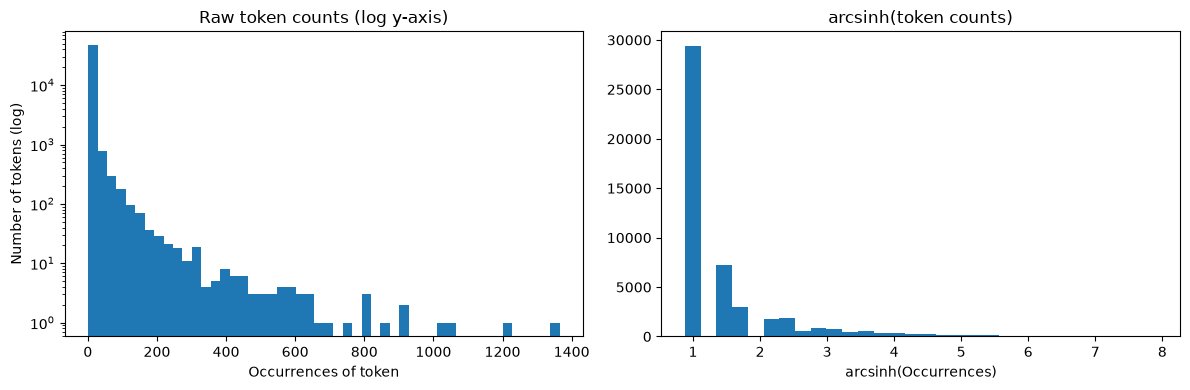

In [ ]:
# Q1
import matplotlib.pyplot as plt
import numpy as np

token_counts = list(token_count.values()) # selecting only the values and then making that into a list


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(token_counts, bins=50)
axes[0].set_yscale('log')
axes[0].set_title('Raw token counts (log y-axis)')
axes[0].set_xlabel('Occurrences of token')
axes[0].set_ylabel('Number of tokens (log)')

axes[1].hist(np.arcsinh(token_counts), bins=30)
axes[1].set_title('arcsinh(token counts)')
axes[1].set_xlabel('arcsinh(Occurrences)')
plt.tight_layout(); plt.show()

# This histogram shows that the distribution is extremely right-skewed and heavy-tailed (Zipf-like). There are 48,691 unique tokens across about 277k total, and about 60% appear only once. The median token appears once, while the most common (“new”) appears 1,365 times. A few tokens account for a large share of all occurrences, and most tokens are rare.

In [52]:
# Q2
import pandas as pd
df = pd.read_parquet('./data/Phishing_clean.parquet')

# splitting the data 80/20:
from sklearn.model_selection import train_test_split
eval_x_raw = df.drop(columns = ['Email Type'])
eval_y = df['Email Type']
(x_train, x_valid, y_train, y_valid,) = train_test_split(eval_x_raw, eval_y, test_size = 0.20, random_state = 7)



In [ ]:
# regression of y - what is R^2 on the test set and training set
from sklearn.linear_model import LinearRegression
sk_fit = LinearRegression().fit(x_train, y_train)

print("R-squared - training set:", round(sk_fit.score(x_train, y_train), 4))
print("R-squared - test set:", round(sk_fit.score(x_valid, y_valid), 4))

# Train R^2 = 0.7657, test R^2 = 0.6682. The ~0.10 gap shows the model is overfitting:
# 2,711 features vs ~14.9k training emails, so it fits some noise in the training set.

R-squared - training set: 0.7657
R-squared - test set: 0.6682


In [ ]:
# What word has the largest coefficients in absolute value and most strongly influence predictions:
coefficients = sk_fit.coef_
word_names = eval_x_raw.columns

coef_df = pd.DataFrame({
    'Word': word_names,
    'Coefficient': coefficients,
    'Absolute_Coef': np.abs(coefficients)
})

top_words = coef_df.sort_values(by = 'Absolute_Coef', ascending=False).head(5)
print('Top words influencing predictions:\n', top_words)

# The word that has the largest coefficient and strongest influence on the prediction is helvetica. Because the non-absolute coefficient is positive, that means that this predicts the email to be a phishing scam email.
# Some other words that have large coefficients are background-image, fontsize, and color codes.

Top words influencing predictions:
                    Word  Coefficient  Absolute_Coef
1406         helvetica,     1.024227       1.024227
1504  background-image:    -1.018343       1.018343
1047         font-size:    -0.997077       0.997077
2094           #000000;     0.924223       0.924223
2666           #331f30;     0.924223       0.924223


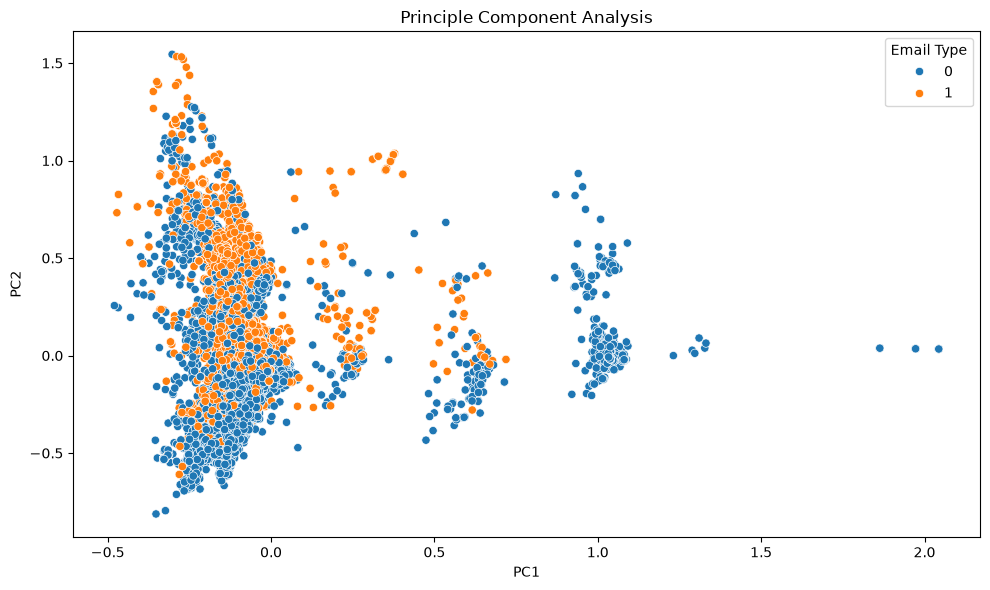

[0.0111309  0.00860986]


In [ ]:
# Q3:
# the email column is already removed in the variable exal_x_raw // two components means that n = 2
from sklearn.decomposition import PCA
import seaborn as sns

pca_emails = PCA(n_components = 2).fit(eval_x_raw)
x_pca_sklearn = pca_emails.transform(eval_x_raw)

# making a df to hold the pca results so we can plot it
pca_df = pd.DataFrame(data = x_pca_sklearn, columns = ['PC1', 'PC2'])
pca_df['Email Type'] = eval_y.values

# plotting the scatter plot
fig, ax = plt.subplots(figsize = (10,6))
sns.scatterplot(
    data = pca_df, 
    x = 'PC1', 
    y = 'PC2',
    hue = 'Email Type',
    ax = ax)

ax.set_title('Principle Component Analysis')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')

plt.tight_layout()
plt.show()

print(pca_emails.explained_variance_ratio_)

# There is a large clump of scam and legitamite emails on the left side of the graph. This means that 2 components do not capture enough variance to differentiate the email types.
# However, there is a large group of legitamite emails with no scam emails on the right side of the graph indicating that high scored on PC1 indicate that the emails are legitament. 
# The two components explain only about 2% of the variance, which is why the classes overlap heavily. There are still patterns: PC1 > 1 is entirely legitimate email (0% scam), and high PC2 skews toward scam (about 69% scam for PC2 > 0.5 vs about 2% for PC2 < -0.5).

In [59]:
# data is already split from Q2 so reusing that

# fitting pca based on the training set:
pca_emails_multiple = PCA(n_components = 2610).fit(x_train)
x_train_pca = pca_emails_multiple.transform(x_train)

#doing pca on the test set:
x_valid_pca = pca_emails_multiple.transform(x_valid)

# linear regression:
pca_lr_model = LinearRegression().fit(x_train_pca, y_train)

print("R-squared - training set:", round(pca_lr_model.score(x_train_pca, y_train), 4))
print("R-squared - test set:", round(pca_lr_model.score(x_valid_pca, y_valid), 4))

# The test set R^2 increased slightly between the linear regression on the original data vs the pca (0.6682 for the original data and 0.6718 for the pca).
# Additionally, the R^ squared value for the training set decreased slightly (0.7657 for the original data and 0.7648 for the pca).
# This means that the test set increased in correctness while the training set decreased meaning it is picking up less random noise. 


R-squared - training set: 0.7648
R-squared - test set: 0.6718


In [ ]:
# Q5:
# There are multiple advantages of using principal components to run the high-dimensional regression.
# By using pca, you are able to filter out noise a lot easier. By using not all principal components, you 
# reduce the amount of noise that is in the analysis and dropping low-variance components acts as regularization, 
# so the model can’t fit noise in those directions. There is also less overfitting, this is because there are less dimensions and the model
# can focus on just signals. This helps the test set and unseen data have more accurate predictions.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

I made one major mistake in phase 1, which I am glad that AI caught because I did not catch it while going through my work in phase 1. I forgot to delete my incorrect code for making the PCA in question 2 because I was confused while doing it, and I realized I was wrong in the first one and just did not delete it. The other suggestions that it recommended were not very revolutionary and were just expanding on my explanations that were already correct. I do feel like AI was making a lot of suggestions that did not need to be made. I thought it was just making up additions to the assignment to have a longer response. I verified the final solution by going through it line by line and making sure that it complemented the slides from class and my general knowledge. I think that doing this assignment alone and then using AI really shows how much AI makes up things when you ask it to make suggestions and other tweaks that are optional. 